# New Zealand Political Party Policies Word Cloud & Analysis

This notebook provides an interactive pipeline to collect publicly accessible policy text from user-configured New Zealand political party websites, analyse term frequencies and relative distinctiveness (TF-IDF), and generate PNG word clouds and CSV exports.

### Analytical Neutrality & Disclaimer
- **Frequency** reflects repetition and corpus size in the collected text.
- **TF-IDF** highlights terms that are relatively distinctive within the *included* party set.
- Neither measure establishes policy quality, intent, truth, or legislative outcomes.
- Collection is limited to eligible first-level HTML links within the configured domain scope. JavaScript-rendered content and PDF documents are not extracted.


In [1]:
import sys
from pathlib import Path
from IPython.display import HTML, Image, display

# Ensure project root and src/ directory are in Python path
project_root = Path.cwd().resolve()
if project_root.name == "notebooks":
    project_root = project_root.parent

src_dir = project_root / "src"
for p in (str(src_dir), str(project_root)):
    if p not in sys.path:
        sys.path.insert(0, p)

from nz_policy_wordcloud import (
    HtmlCrawler,
    HtmlExtractor,
    OutputManager,
    TextCleaner,
    calculate_term_frequencies,
    calculate_tfidf_ranks,
    load_config_from_yaml,
    make_run_directory,
)

print(f"Working directory: {project_root}")
print(f"Package location: {src_dir}")

Working directory: /Users/vrbabu/Library/Mobile Documents/com~apple~CloudDocs/code/NZ_Election_Policies_Word_Cloud
Package location: /Users/vrbabu/Library/Mobile Documents/com~apple~CloudDocs/code/NZ_Election_Policies_Word_Cloud/src


## 1. Load and Validate Configuration

Load crawler settings, exclusion filters, and party starting URLs from `config.yaml`.
Input validation ensures domain and URL rules are checked offline before any network requests are sent.


In [2]:
config_path = project_root / "config.yaml"
config_result = load_config_from_yaml(config_path)
if config_result.is_err():
    raise ValueError(f"Configuration error: {config_result.unwrap_err()}")
config = config_result.unwrap()

print(f"Loaded configuration from: {config_path.name}")
print(f"Crawler delay: {config.crawler_settings.delay_seconds}s | Timeout: {config.crawler_settings.request_timeout_seconds}s")
print(f"Configured Parties ({len(config.parties)}):")
for p in config.parties:
    print(f"  - [{p.id}] {p.name}: {len(p.starting_urls)} starting URL(s)")

Loaded configuration from: config.yaml
Crawler delay: 1.0s | Timeout: 10.0s
Configured Parties (8):
  - [national] National Party: 1 starting URL(s)
  - [labour] Labour Party: 1 starting URL(s)
  - [greens] Green Party: 1 starting URL(s)
  - [act] ACT New Zealand: 1 starting URL(s)
  - [nz_first] New Zealand First: 1 starting URL(s)
  - [te_pati_maori] Te Pāti Māori: 1 starting URL(s)
  - [top] The Opportunities Party: 1 starting URL(s)
  - [alcp] Aotearoa Legalise Cannabis Party: 1 starting URL(s)


## 2. Initialize Run Directory

Creates an isolated, non-overwriting timestamped directory under `outputs/run_YYYYMMDD_HHMMSS/` to store crawl manifests, raw extracted texts, CSV rankings, and PNG word clouds.


In [3]:
run_dir = make_run_directory(base_dir=project_root / "outputs")
output_manager = OutputManager(run_dir)
print(f"Run directory created: {run_dir}")

Run directory created: /Users/vrbabu/Library/Mobile Documents/com~apple~CloudDocs/code/NZ_Election_Policies_Word_Cloud/outputs/run_20261029_183330


## 3. Web Crawling (First-Level Links Only)

Fetches each starting page and discovers immediate first-level links within allowed hostnames, obeying robots.txt and exclusions.


In [4]:
crawler = HtmlCrawler(
    crawler_config=config.crawler_settings,
    exclusion_config=config.exclusions,
)

print(f"Starting polite first-level crawl across {len(config.parties)} configured parties...")
print(f"Polite delay between requests to same host: {config.crawler_settings.delay_seconds}s\n")

# Pass print as on_progress callback for real-time progress updates
manifest = crawler.crawl_all_parties(config.parties, on_progress=print)

# Save crawl manifest CSV
manifest_csv_path = output_manager.save_crawl_manifest(manifest)
print(f"\nCrawl completed. Manifest saved to: {manifest_csv_path.name}")
print(f"Total Attempted: {manifest.total_attempted} | Succeeded: {manifest.total_succeeded} | Failed: {manifest.total_failed}")

Starting polite first-level crawl across 8 configured parties...
Polite delay between requests to same host: 1.0s


>>> [1/8] Processing Party: National Party (national)
[national] Starting crawl for 'National Party' (1 starting URL(s))...
[national] Processing starting page: https://www.national.org.nz/plan
[national] Fetching: https://www.national.org.nz/plan ...
[national] [OK] Fetched starting page (200, 186496 bytes). Discovering links...
[national] Found 41 links on starting page (28 eligible first-level policy links queued).
[national] [1/28] Fetching: https://www.national.org.nz/ ...
[national] [1/28] [OK] https://www.national.org.nz/ (status 200, 174136 bytes)
[national] [2/28] Fetching: https://www.national.org.nz/overseas-voting ...
[national] [2/28] [OK] https://www.national.org.nz/overseas-voting (status 200, 121064 bytes)
[national] [3/28] Fetching: https://www.national.org.nz/team ...
[national] [3/28] [OK] https://www.national.org.nz/team (status 200, 240482 bytes)
[nat

## 4. Review Crawl Status and Skips/Failures

Inspect crawling outcomes for each party without halting processing.


In [5]:
for party in config.parties:
    records = manifest.records_for_party(party.id)
    succ = sum(1 for r in records if r.success)
    fail = sum(1 for r in records if not r.success)
    print(f"Party [{party.id}] '{party.name}': {succ} succeeded, {fail} failed")
    # Show failed pages if any
    for r in records:
        if not r.success:
            print(f"    FAILED: {r.attempted_url} (reason: {r.error_message})")

Party [national] 'National Party': 29 succeeded, 0 failed
Party [labour] 'Labour Party': 54 succeeded, 0 failed
Party [greens] 'Green Party': 80 succeeded, 1 failed
    FAILED: https://www.greens.org.nz/cdn-cgi/l/email-protection (reason: HTTP error 404)
Party [act] 'ACT New Zealand': 12 succeeded, 0 failed
Party [nz_first] 'New Zealand First': 52 succeeded, 0 failed
Party [te_pati_maori] 'Te Pāti Māori': 32 succeeded, 2 failed
    FAILED: https://www.maoriparty.org.nz/cdn-cgi/l/email-protection (reason: HTTP error 404)
    FAILED: https://www.maoriparty.org.nz/users/facebook/connect?page_id=2890&scope=public_profile%2Cemail (reason: Disallowed by robots.txt)
Party [top] 'The Opportunities Party': 27 succeeded, 1 failed
    FAILED: https://www.opportunity.org.nz/cdn-cgi/l/email-protection (reason: HTTP error 404)
Party [alcp] 'Aotearoa Legalise Cannabis Party': 9 succeeded, 0 failed


## 5. HTML Text Extraction

Extracts main readable policy text using Trafilatura with BeautifulSoup article fallback, stripping boilerplate, navigation, and script tags.
Raw extracted texts are saved to disk with metadata headers linking to original source URLs.


In [6]:
extractor = HtmlExtractor()
documents = extractor.extract_from_manifest(manifest)

saved_doc_paths = output_manager.save_extracted_documents(documents, extractor)
print(f"Extracted substantive content from {len(documents)} pages.")
print(f"Saved raw text records to: {run_dir / 'extracted_text'}")

# Print sample of extracted document titles/word counts
for doc in documents[:5]:
    print(f"  - [{doc.party_id}] {doc.source_url} ({doc.word_count} words, status: {doc.status.value})")

Extracted substantive content from 293 pages.
Saved raw text records to: /Users/vrbabu/Library/Mobile Documents/com~apple~CloudDocs/code/NZ_Election_Policies_Word_Cloud/outputs/run_20261029_183330/extracted_text
  - [national] https://www.national.org.nz/plan (670 words, status: success_primary)
  - [national] https://www.national.org.nz/ (30 words, status: success_primary)
  - [national] https://www.national.org.nz/overseas-voting (437 words, status: success_primary)
  - [national] https://www.national.org.nz/team (35 words, status: success_primary)
  - [national] https://www.national.org.nz/team/christopherluxon (201 words, status: success_primary)


## 6. Text Cleaning & Tokenisation

Cleans text by applying NFKC Unicode normalisation, lowercasing, punctuation stripping, Te Reo Māori macron preservation (`ā, ē, ī, ō, ū`), and removal of standard and custom stop words.


In [7]:
cleaner = TextCleaner(custom_stop_words=config.exclusions.custom_stop_words)

# Group extracted text by party
party_tokens: dict[str, list[str]] = {}
party_clean_texts: dict[str, str] = {}

for party in config.parties:
    party_docs = [d for d in documents if d.party_id == party.id and d.text]
    combined_raw = " ".join(d.text for d in party_docs)
    tokens = cleaner.tokenize(combined_raw)
    party_tokens[party.id] = tokens
    party_clean_texts[party.id] = cleaner.clean_text(combined_raw)
    print(f"Party [{party.id}]: {len(party_docs)} documents -> {len(tokens)} cleaned tokens")

Party [national]: 28 documents -> 5163 cleaned tokens
Party [labour]: 54 documents -> 31714 cleaned tokens
Party [greens]: 80 documents -> 25820 cleaned tokens
Party [act]: 12 documents -> 1147 cleaned tokens
Party [nz_first]: 52 documents -> 17373 cleaned tokens
Party [te_pati_maori]: 31 documents -> 2011 cleaned tokens
Party [top]: 27 documents -> 8278 cleaned tokens
Party [alcp]: 9 documents -> 6767 cleaned tokens


## 7. Term Frequency & TF-IDF Analysis

Calculates:
1. **Raw Term Frequency** with deterministic tie-breaking (count DESC, term ASC).
2. **TF-IDF Scores** across all included parties to highlight distinctive terms.
CSVs containing top-20 and all terms are exported for inspection.


In [8]:
# 1. Frequency calculation
frequency_ranks = {
    party.id: calculate_term_frequencies(party_tokens[party.id], party_id=party.id, top_n=20)
    for party in config.parties
}
freq_top_path, freq_all_path = output_manager.save_frequency_csv(frequency_ranks, top_n=20)
print(f"Frequency CSVs saved: {freq_top_path.name}, {freq_all_path.name}")

# 2. TF-IDF calculation
tfidf_ranks = calculate_tfidf_ranks(party_clean_texts, top_n=20)
tfidf_top_path, tfidf_all_path = output_manager.save_tfidf_csv(tfidf_ranks, top_n=20)
print(f"TF-IDF CSVs saved: {tfidf_top_path.name}, {tfidf_all_path.name}")

Frequency CSVs saved: frequency_top20.csv, frequency_all.csv
TF-IDF CSVs saved: tfidf_top20.csv, tfidf_all.csv


## 8. Generate and Display Word Clouds

Word clouds are rendered for each party (Frequency and TF-IDF) with clear descriptive disclaimers.


File: national_frequency.png


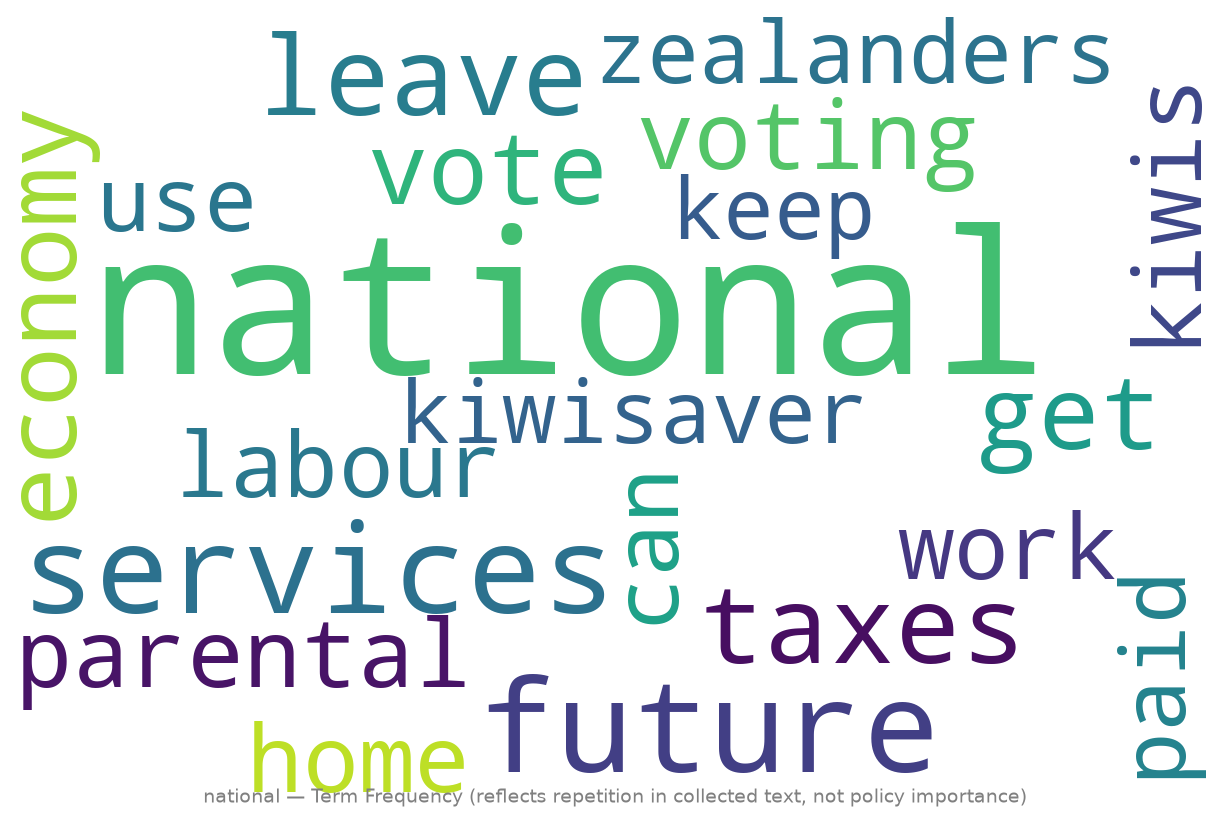

File: national_tfidf.png


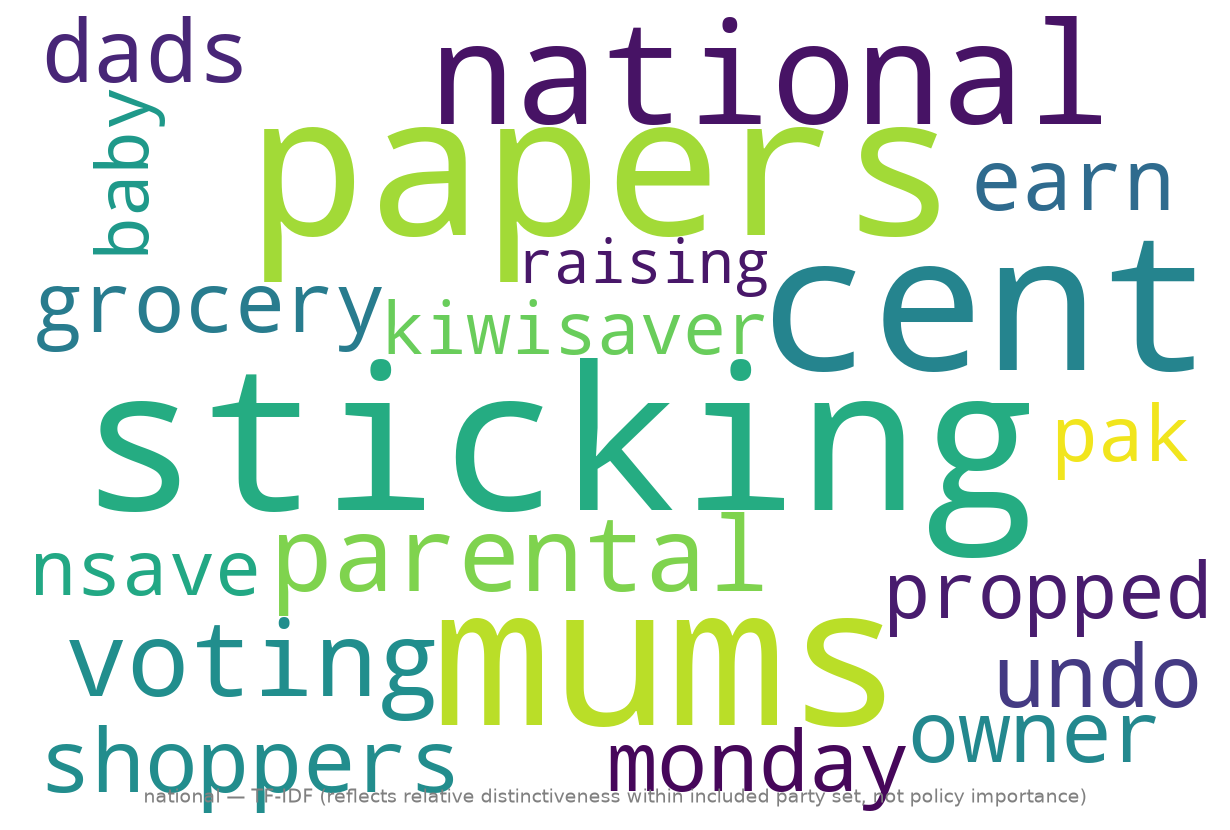

File: labour_frequency.png


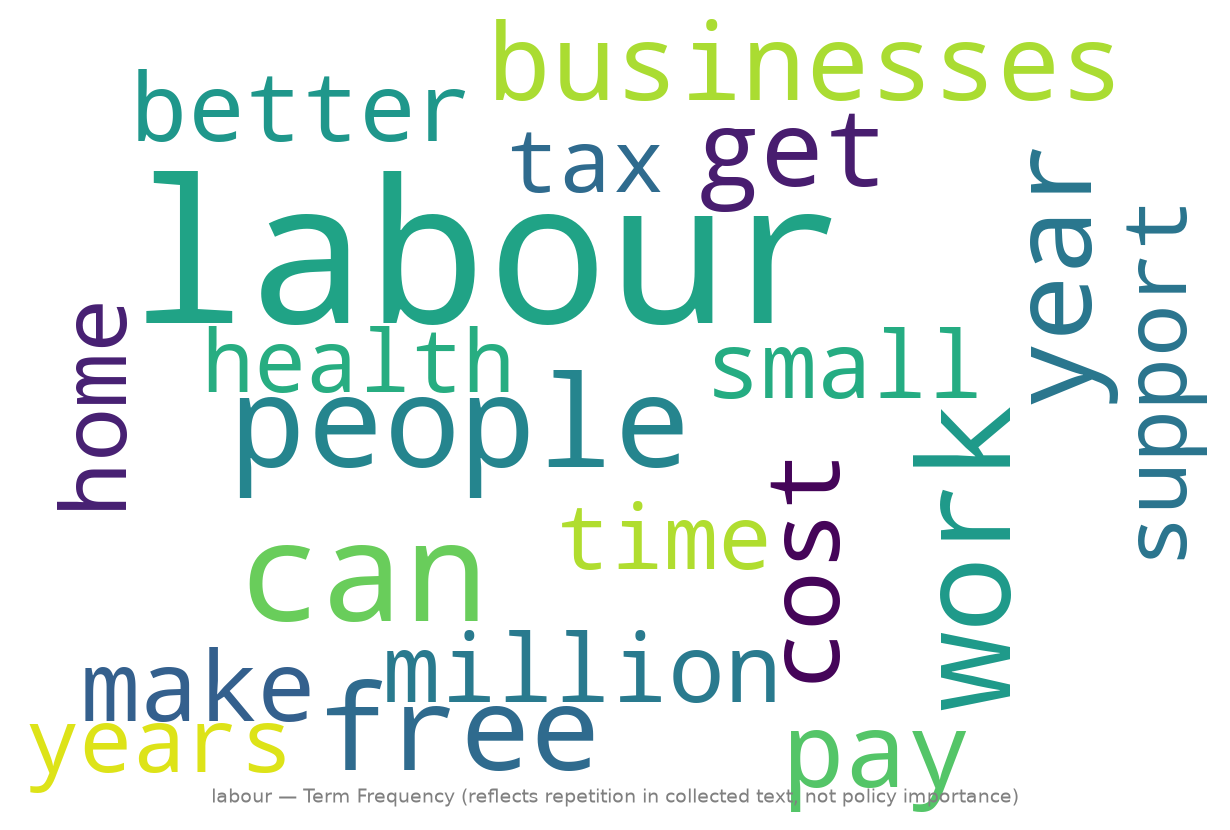

File: labour_tfidf.png


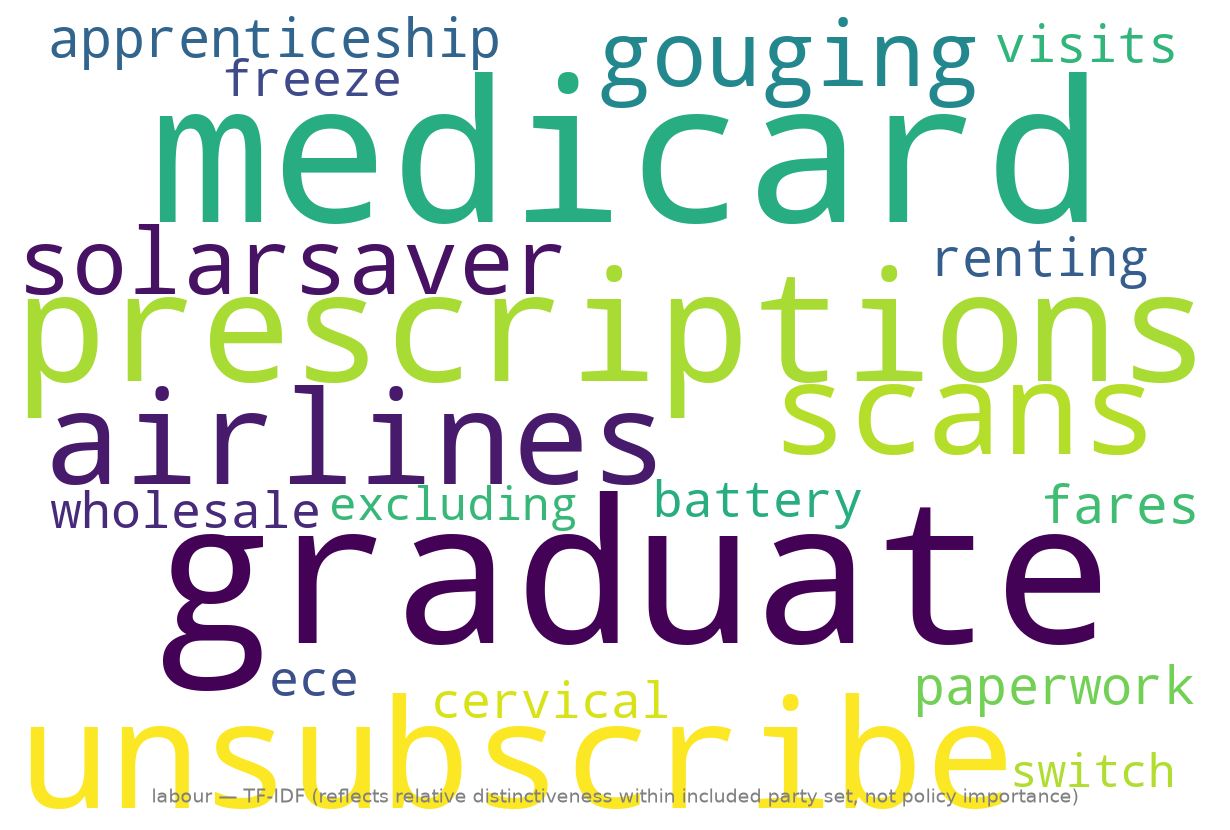

File: greens_frequency.png


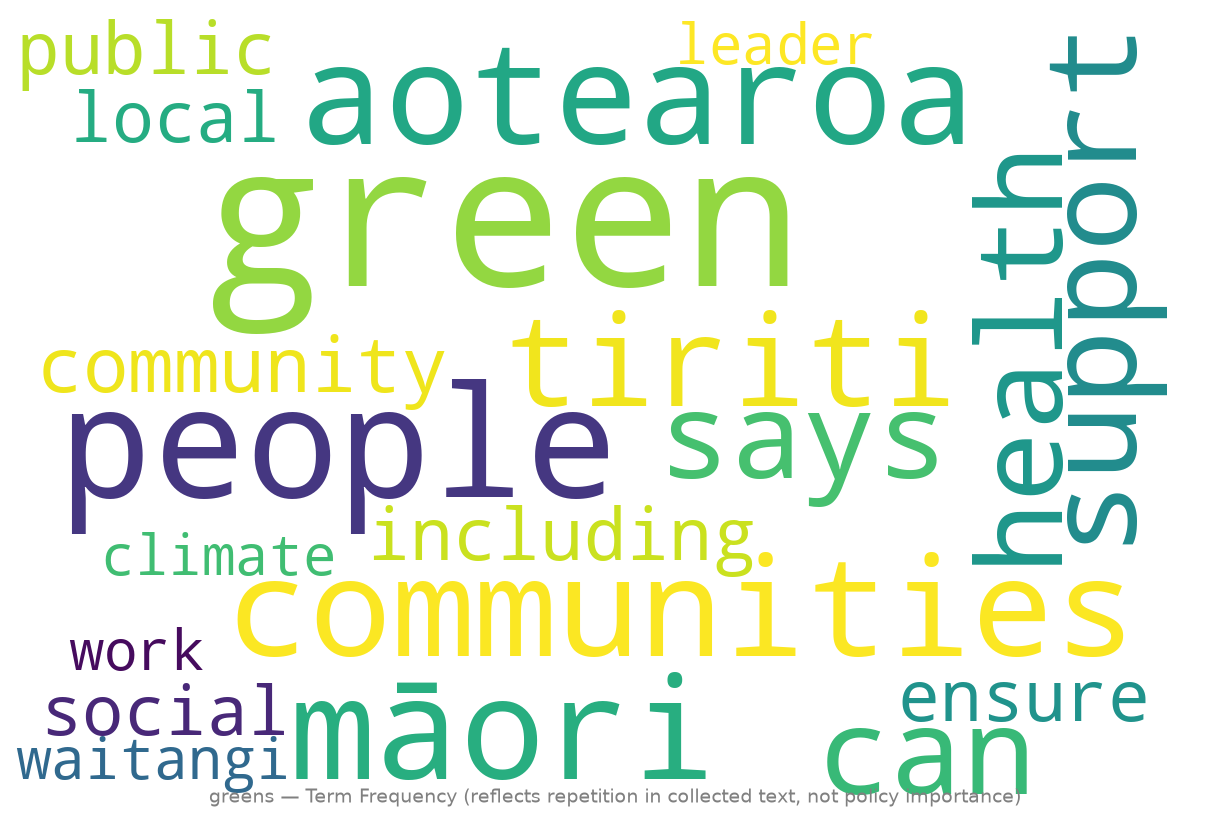

File: greens_tfidf.png


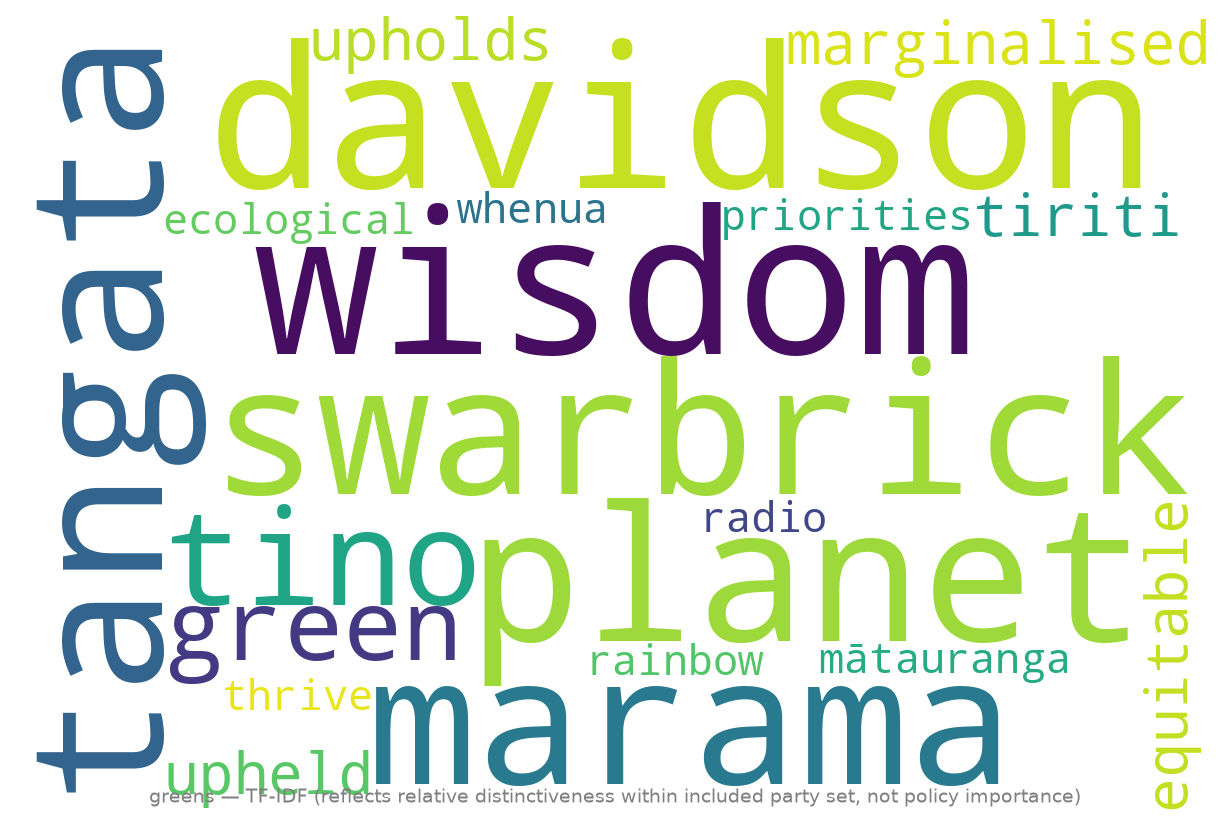

File: act_frequency.png


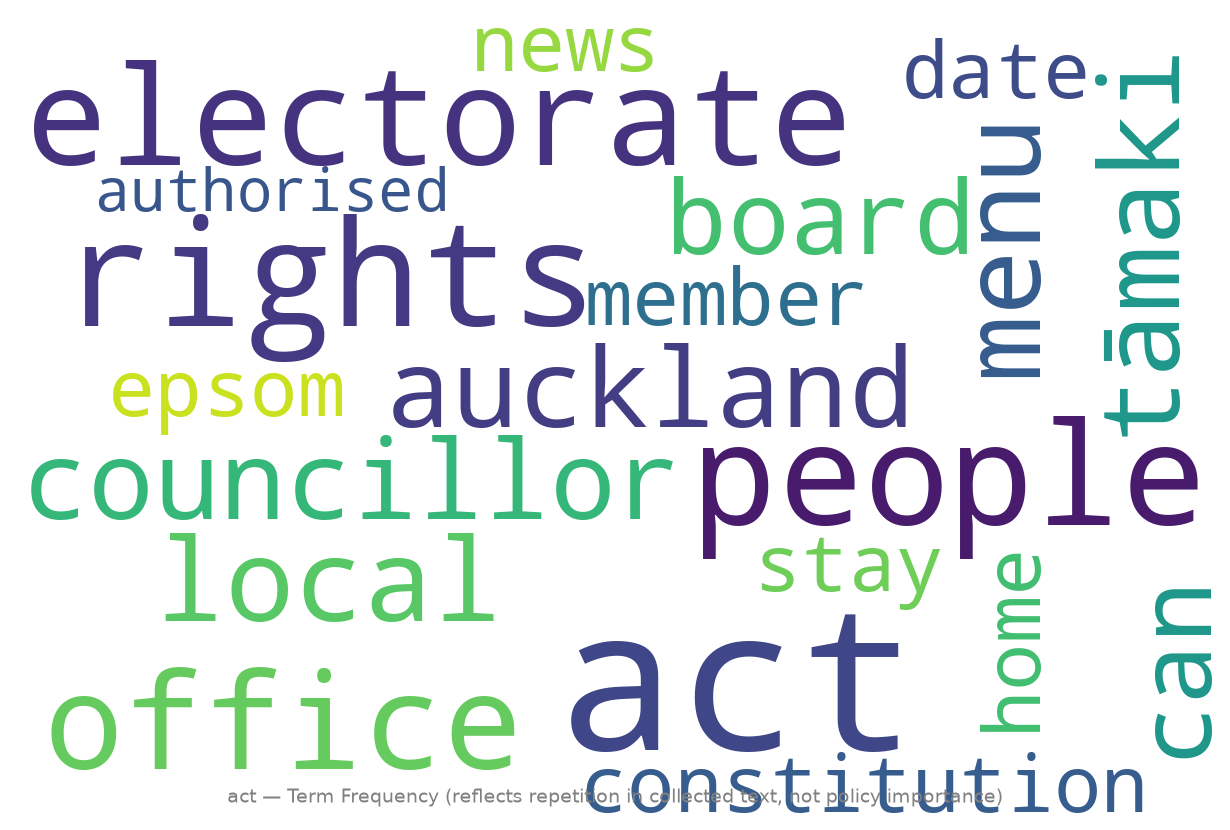

File: act_tfidf.png


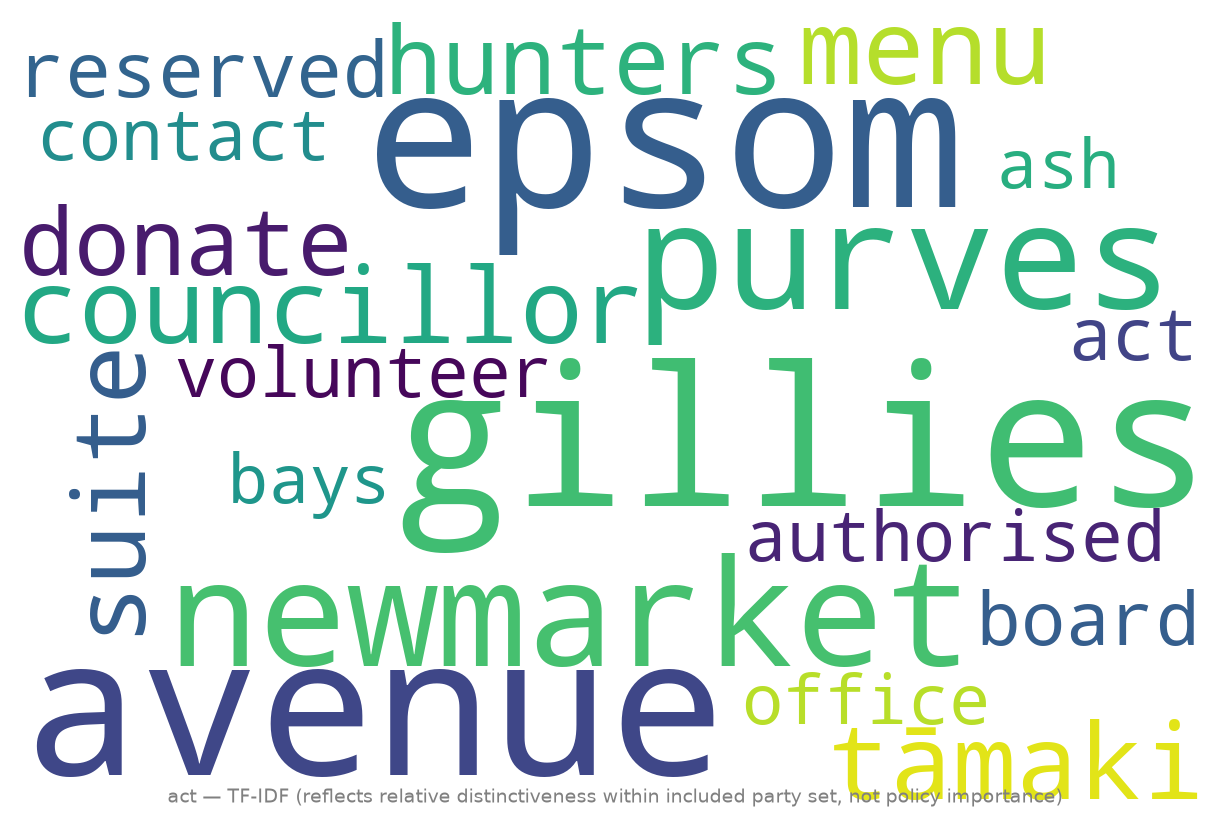

File: nz_first_frequency.png


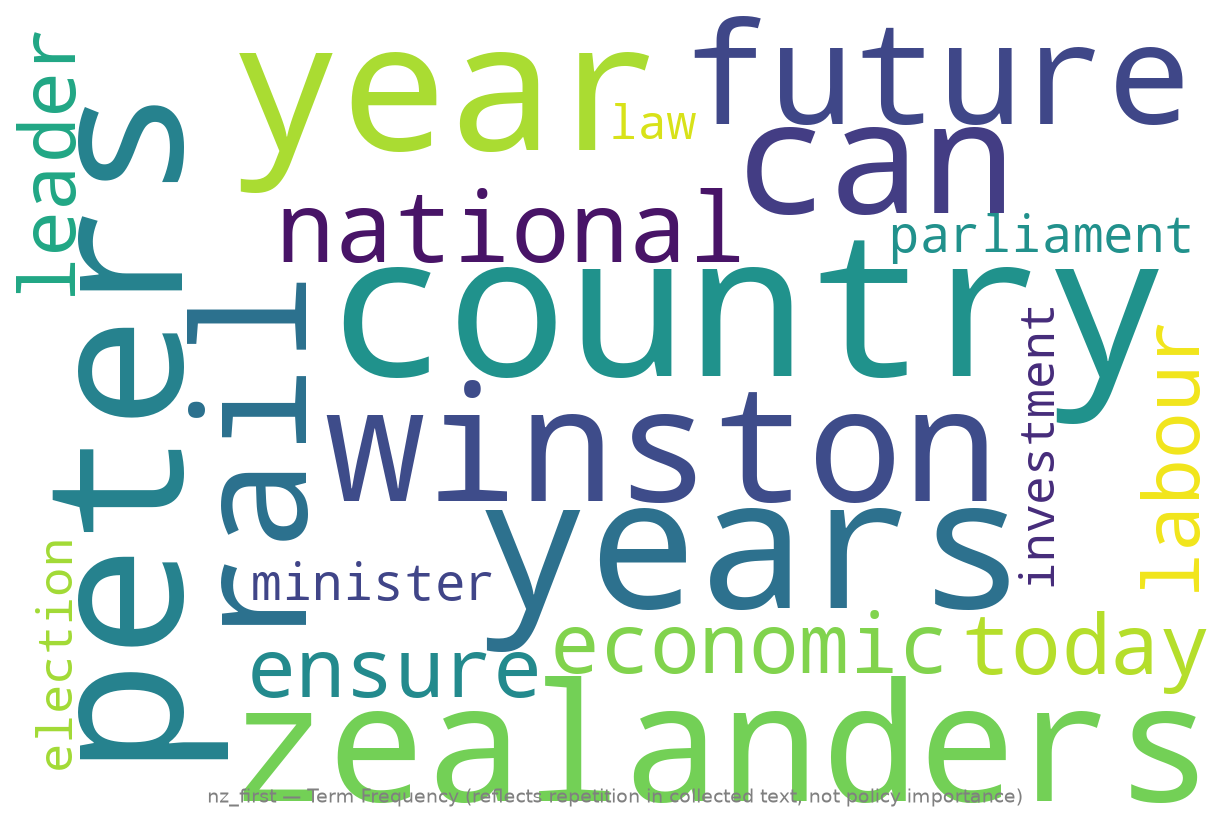

File: nz_first_tfidf.png


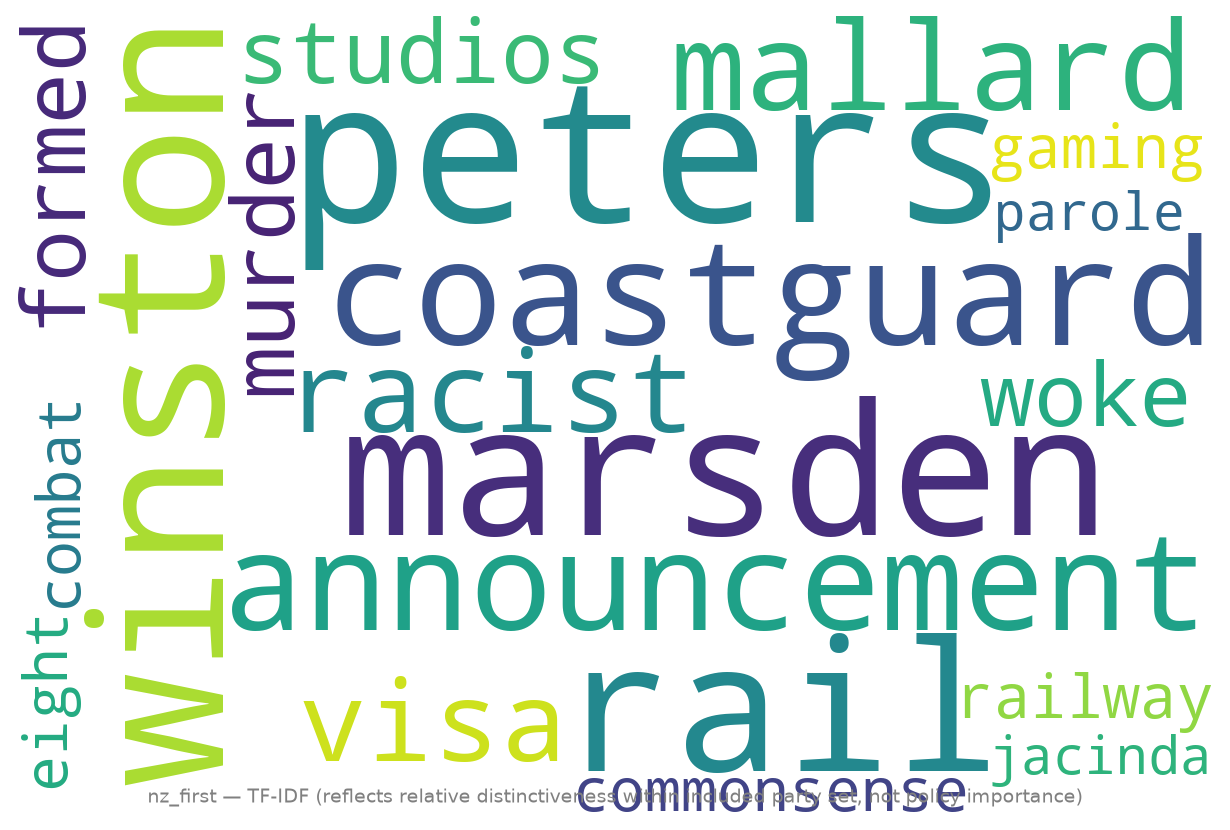

File: te_pati_maori_frequency.png


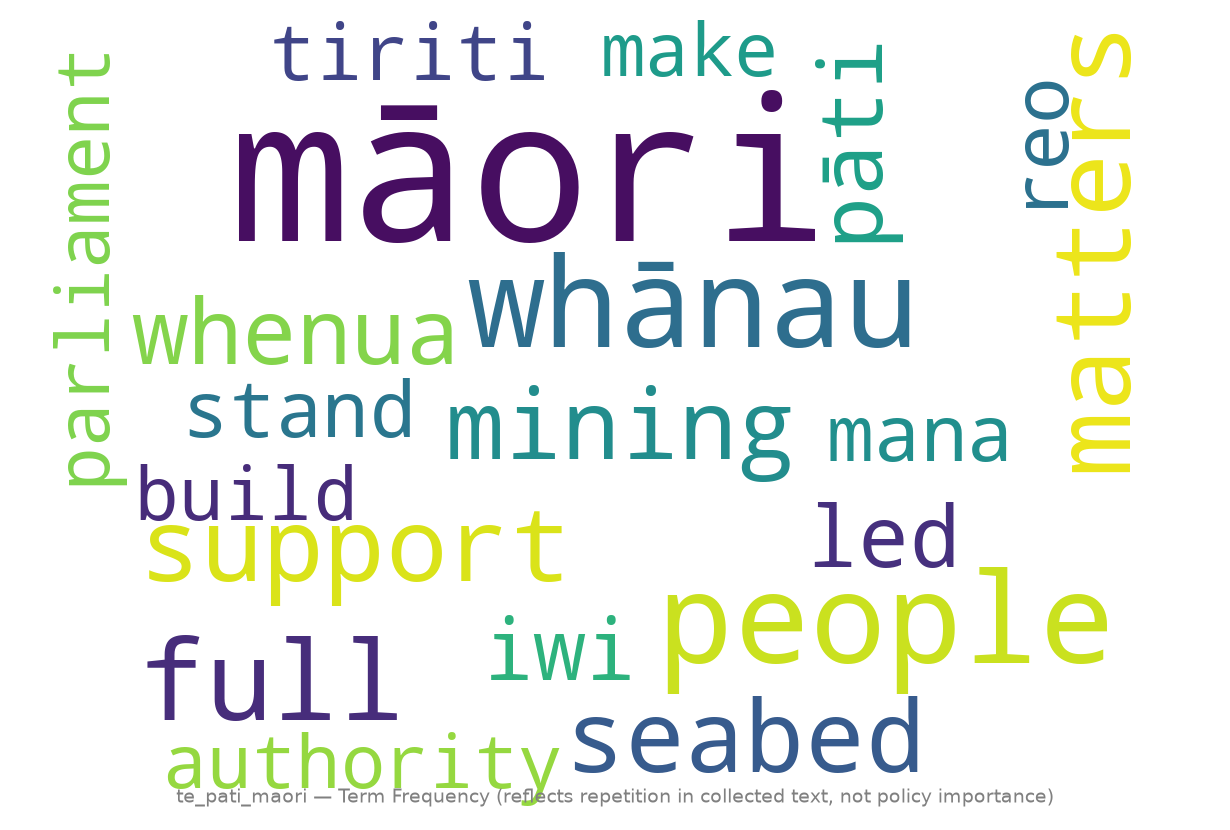

File: te_pati_maori_tfidf.png


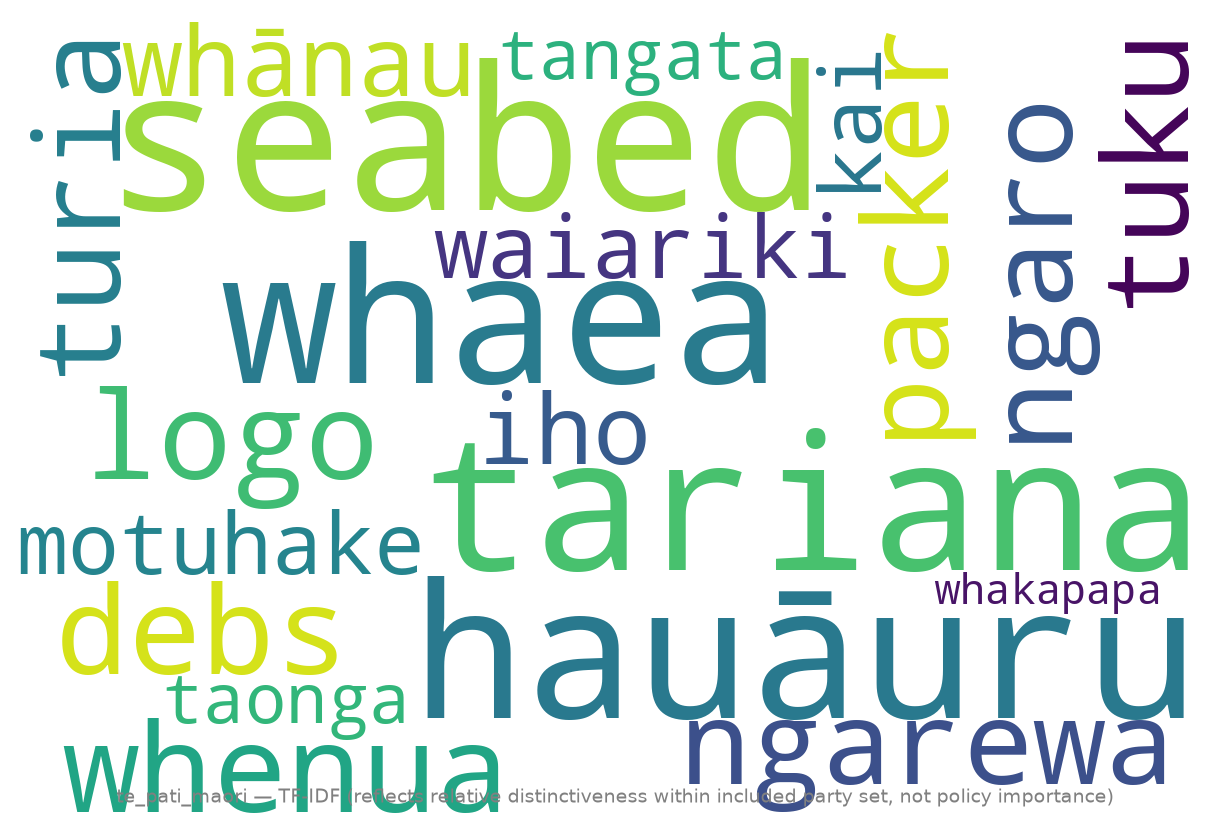

File: top_frequency.png


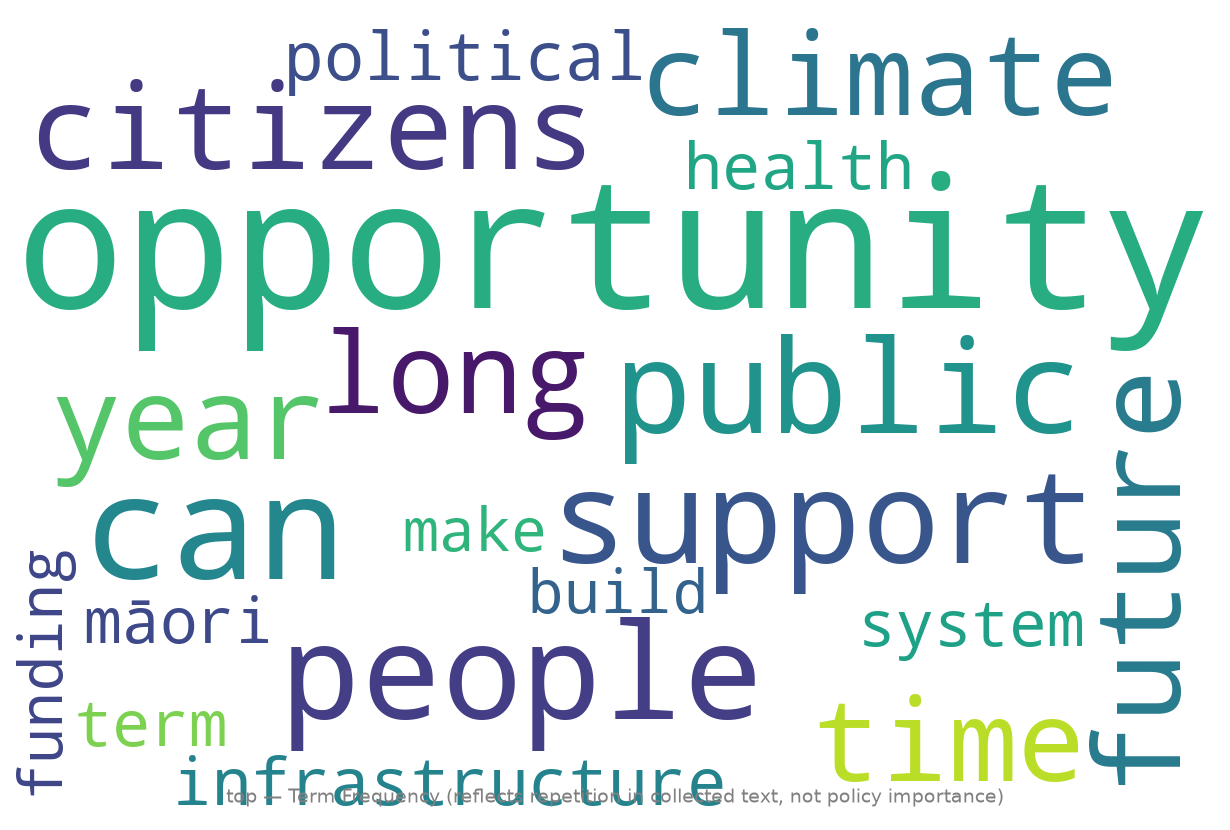

File: top_tfidf.png


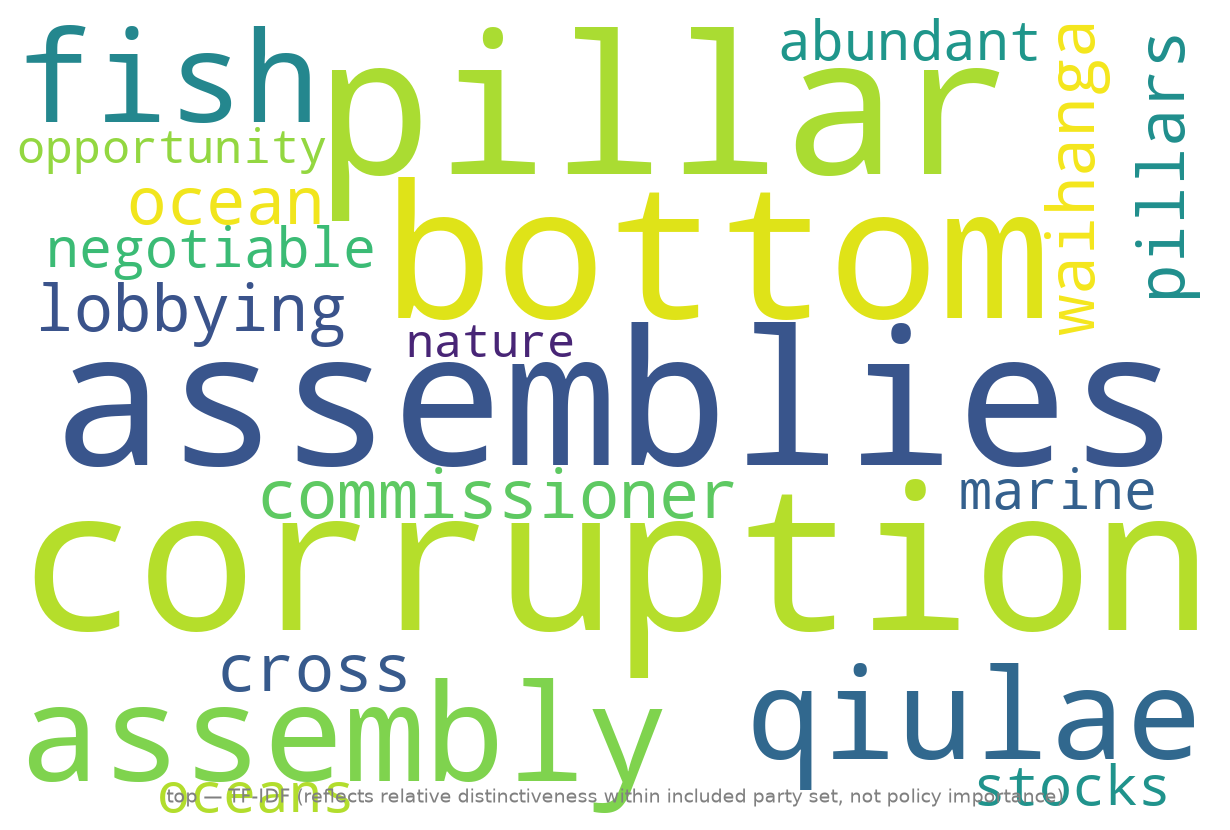

File: alcp_frequency.png


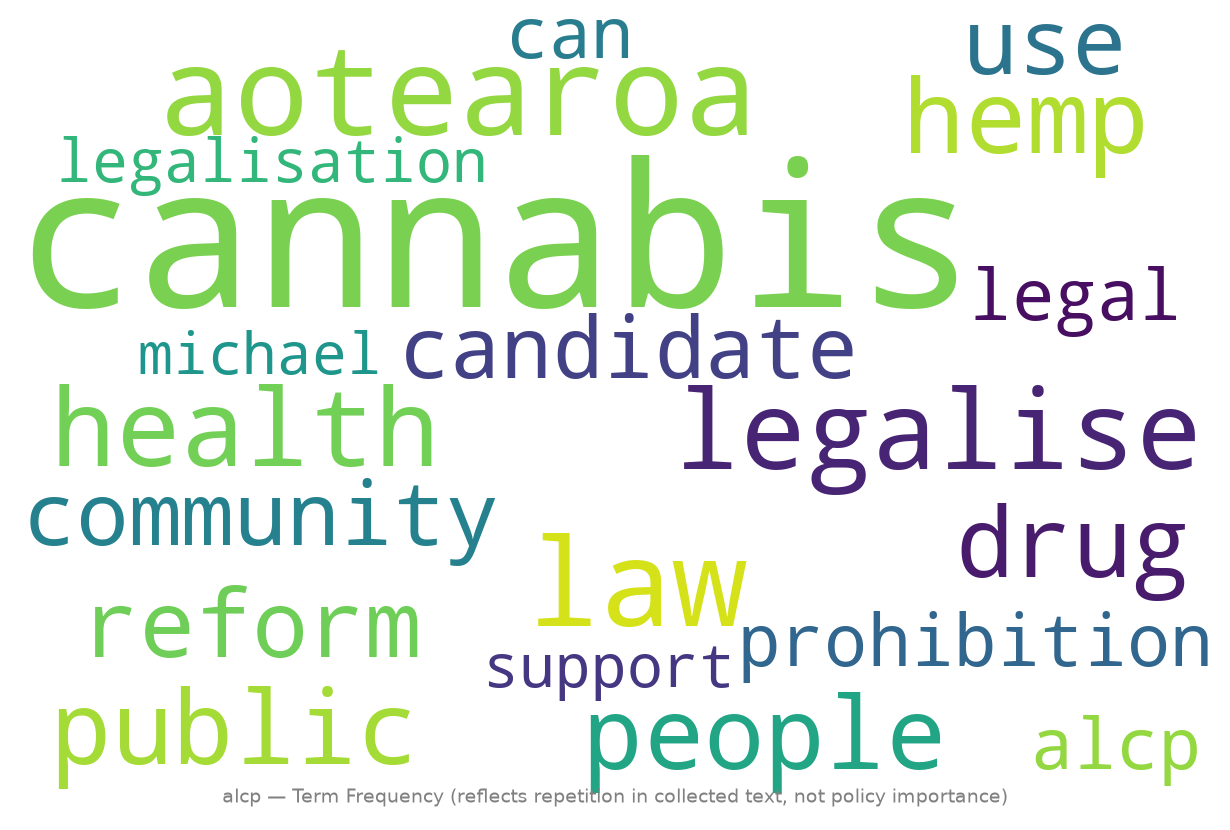

File: alcp_tfidf.png


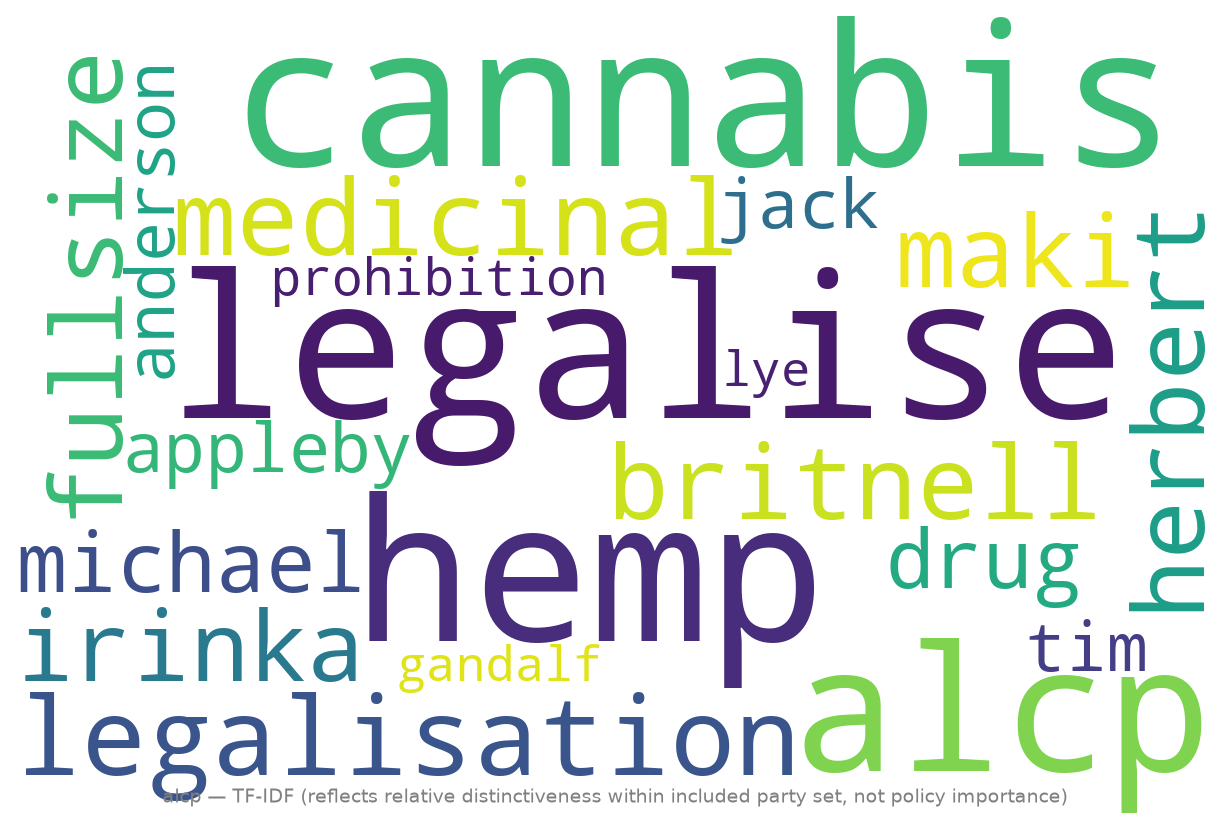

In [9]:
saved_clouds = output_manager.save_wordclouds(frequency_ranks, tfidf_ranks)

for party in config.parties:
    party_id = party.id
    paths = saved_clouds.get(party_id, [])
    if not paths:
        display(HTML(f"<div style='font-size: 16px; font-weight: bold; margin-top: 20px;'>=== Word Clouds for {party.name} ({party_id}) ===</div>"))
        print(f"No word clouds generated for [{party_id}] (no extracted terms).\n")
        continue

    # Main party section header in bold size 16 font
    display(HTML(f"<div style='font-size: 16px; font-weight: bold; margin-top: 25px; margin-bottom: 10px;'>=== Word Clouds for {party.name} ({party_id}) ===</div>"))

    for p in paths:
        # Determine method subtitle
        if "frequency" in p.name.lower():
            method_title = f"{party.name} - Term Frequency"
        elif "tfidf" in p.name.lower():
            method_title = f"{party.name} - Term Frequency - Inverse Document Frequency"
        else:
            method_title = f"{party.name} - Word Cloud"

        # Display method heading in bold size 12 font
        display(HTML(f"<div style='font-size: 12px; font-weight: bold; margin-top: 10px; margin-bottom: 4px;'>{method_title}</div>"))
        print(f"File: {p.name}")
        display(Image(filename=str(p), width=800))

## 9. Run Summary and Audit Log

Saves an audit metadata record `run_summary.json` containing total counts, party lists, timestamps, and analytical limitations.


In [ ]:
summary_metadata = {
    "run_directory": str(run_dir),
    "parties_configured": [p.id for p in config.parties],
    "total_pages_attempted": manifest.total_attempted,
    "total_pages_succeeded": manifest.total_succeeded,
    "total_pages_failed": manifest.total_failed,
    "total_documents_extracted": len(documents),
    "frequency_top_terms": {
        pid: [r.term for r in ranks[:5]] for pid, ranks in frequency_ranks.items()
    },
    "tfidf_top_terms": {
        pid: [r.term for r in ranks[:5]] for pid, ranks in tfidf_ranks.items()
    },
}

summary_path = output_manager.save_run_summary(summary_metadata)
print(f"Run summary written to: {summary_path}")
print("Run completed successfully.")